# Rates Lab for the Colombian Peso and Sterling: IBR and TES versus Gilt and SONIA Curves, Curve Fits under Leave-One-Tenor-Out Validation, Dynamic Forecasts, and Key-Rate Risk of Overnight-Index Swaps

A rates desk needs three things from a yield curve: a smooth curve through the few rates the market actually quotes, a view of how that curve may move, and the sensitivity of each position to every part of it. This notebook builds all three for two very different markets. The Colombian peso curve is short of data: Banco de la República publishes the interbank reference rate (IBR) from overnight to twelve months and zero-coupon yields of government bonds (TES) at one, five and ten years, and rates have swung from 1.75% to 13.25% and back in five years. The sterling curve is rich: the Bank of England publishes fitted zero-coupon gilt and SONIA overnight-index-swap (OIS) curves at half-year steps out to 25–40 years.

**What it does.**

1. It downloads month-end curves: since 2016 for the peso (when the six-month IBR starts) and since 2008 for gilts and 2016 for SONIA swaps: IBR and TES zero-coupon rates and the policy rate from Banco de la República's statistics service, and the Bank of England's nominal gilt and SONIA OIS spot curves.
2. It decomposes monthly curve changes into principal components (level, slope, curvature) in each market and measures how much the two markets move together.
3. It compares four ways of drawing a curve through the quoted points: Nelson–Siegel, Nelson–Siegel–Svensson, a cubic spline and a Gaussian process, by leaving out one quoted tenor at a time and predicting it.
4. It forecasts the curve one month ahead with a random walk, the dynamic Nelson–Siegel model of Diebold and Li, and LightGBM, out of sample from 2015 for gilts and 2019 for the peso.
5. It values five-year receive-fixed OIS positions in both currencies (IBR and SONIA), computes their DV01 and key-rate DV01s, measures their one-month 99% value-at-risk from historical curve moves, and hedges level and slope risk with two other swaps.

**Data.** Banco de la República (suameca statistics service): monetary policy rate, IBR overnight to 12 months, TES zero-coupon rates at 1, 5 and 10 years. Bank of England: nominal government liability curve and OIS (SONIA) curve, month-end.

**Methods.** Principal component analysis, Nelson–Siegel and Svensson fits, cubic splines, Gaussian-process regression, leave-one-tenor-out validation, the Diebold–Li dynamic factor model, LightGBM, OIS pricing, DV01 and key-rate DV01, historical value-at-risk and principal-component hedging.

**Key output.** Variance shares of curve factors and cross-market correlation; out-of-sample errors of every curve fit and forecast by tenor; par rates, DV01, key-rate profiles and hedged and unhedged value-at-risk of the two swaps.

## 1. Curves, quotes and conventions

**Colombian peso.** The IBR is the rate at which eight banks quote to lend and borrow pesos; it is the floating leg of Colombian interest-rate swaps (overnight-indexed swaps pay the compounded overnight IBR). It is published as a nominal rate on an actual/360 basis for terms of one day to twelve months (the twelve-month rate since 2022). Banco de la República also fits a zero-coupon curve to TES government bonds and publishes it at 1, 5 and 10 years as effective annual yields. There is no public curve of IBR swap rates beyond one year, so the peso curve here joins IBR rates up to one year with TES zero-coupon rates beyond; TES yields include a sovereign term and credit premium over IBR swaps, so the long end is a proxy for the swap curve, not the swap curve itself.

**Sterling.** The Bank of England fits smooth spline curves to gilt prices (nominal government liability curve) and to SONIA OIS rates and publishes zero-coupon spot rates at half-year steps (monthly steps at the short end).

**Common basis.** All rates are converted to continuously compounded zero rates (IBR: ln(1 + *r d*/360) × 365/*d*; TES: ln(1 + *r*); Bank of England rates are used as published, as zero-coupon spot rates). Discount factors are *P*(*t*) = exp(−*z*(*t*) *t*).

**Nelson–Siegel.** *z*(τ) = β<sub>0</sub> + β<sub>1</sub> (1 − e<sup>−λτ</sup>)/(λτ) + β<sub>2</sub> [(1 − e<sup>−λτ</sup>)/(λτ) − e<sup>−λτ</sup>]: level, slope and curvature loadings. Svensson adds a second curvature term with its own decay.

## 2. Setup

In [1]:
# --- macOS safety switch (must run before any scientific import)
# Several libraries (PyTorch, LightGBM, scikit-learn, NumPy builds) ship their
# own OpenMP runtime.
# On Apple Silicon two copies in one process can make Jupyter report "the
# kernel crashed".
import os

os.environ.setdefault("KMP_DUPLICATE_LIB_OK", "TRUE")


# --- Standard library
import datetime as dt
import io
import re
import time
import warnings
from pathlib import Path

# --- Third-party
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import plotly.graph_objects as go
import requests
from dotenv import find_dotenv, load_dotenv
from fredapi import Fred
from plotly.subplots import make_subplots
import zipfile
import certifi
import lightgbm as lgb
from scipy.interpolate import CubicSpline
from scipy.optimize import minimize, minimize_scalar
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import RBF, ConstantKernel, WhiteKernel
from sklearn.exceptions import ConvergenceWarning

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.float_format", lambda v: f"{v:,.2f}")

PROJECT_DIR = Path.cwd()
DATA_DIR, OUT_DIR = PROJECT_DIR / "data", PROJECT_DIR / "outputs"
DATA_DIR.mkdir(exist_ok=True)
OUT_DIR.mkdir(exist_ok=True)

load_dotenv(find_dotenv(usecwd=True))
FRED_API_KEY = os.getenv("FRED_API_KEY", "").strip()
if not FRED_API_KEY:
    raise RuntimeError(
        "FRED_API_KEY not found. Create the .env file at the repo root (see"
        " .env.example)."
    )
fred = Fred(api_key=FRED_API_KEY)
BROWSER_HEADERS = {
    "User-Agent": (
        "Mozilla/5.0 (Macintosh; Intel Mac OS X 10_15_7) Chrome/130.0"
        " Safari/537.36"
    )
}

SEED = 2023
rng = np.random.default_rng(SEED)
BANREP = "https://suameca.banrep.gov.co/graficador-series/rest/graficadorService/consultaSerieParaGraficar?idSerie={}"
BANREP_SERIES = {
    "policy": 59,
    "ibr_on": 241,
    "ibr_1m": 242,
    "ibr_3m": 243,
    "ibr_6m": 16560,
    "ibr_12m": 16562,
    "tes_1y": 15272,
    "tes_5y": 15273,
    "tes_10y": 15274,
}
BOE = "https://www.bankofengland.co.uk/-/media/boe/files/statistics/yield-curves/{}.zip"
START = "2008-01-31"
COP_TENORS = {
    "ibr_on": 1 / 365,
    "ibr_1m": 1 / 12,
    "ibr_3m": 0.25,
    "ibr_6m": 0.5,
    "ibr_12m": 1.0,
    "tes_1y": 1.0,
    "tes_5y": 5.0,
    "tes_10y": 10.0,
}
GILT_TENORS = [0.5, 1, 2, 3, 5, 7, 10, 15, 20, 25]
OIS_TENORS = [1 / 12, 0.25, 0.5, 1, 2, 3, 5, 7, 10, 15, 20, 25]
FORECAST_START = "2015-01-31"
# the 6-month IBR starts in May 2016
FORECAST_START_COP = "2019-01-31"
NOTIONAL = 100_000_000  # in each currency
SWAP_YEARS = 5

print(f"lightgbm {lgb.__version__} · run on {dt.date.today():%Y-%m-%d}")

lightgbm 4.7.0 · run on 2026-11-18


In [2]:
# --- Round only the numeric columns (dates and text are left as they are)
def round_num(df, n=2):
    num = df.select_dtypes("number").columns
    return df.assign(**{c: df[c].round(n) for c in num})


# --- Caching helper: every download is stored in data/ and reused for 12 hours
def cached(name, fetch, max_age_hours=12):
    path = DATA_DIR / f"{name}.parquet"
    if (
        path.exists()
        and (time.time() - path.stat().st_mtime) / 3600 < max_age_hours
    ):
        return pd.read_parquet(path)
    try:
        frame = fetch()
        frame.to_parquet(path)
        return frame
    except Exception as err:
        if path.exists():
            print(
                f"⚠️  {name}: download failed ({type(err).__name__}); using"
                " cached copy"
            )
            return pd.read_parquet(path)
        raise


# --- Chart style
PALETTE = [
    "#2a78d6",
    "#eb6834",
    "#1baf7a",
    "#eda100",
    "#e87ba4",
    "#008300",
    "#6250d6",
    "#e34948",
]
INK, INK_2, GRID, SURFACE = "#0b0b0b", "#52514e", "#e4e3df", "#fcfcfb"
STATUS = {"green": "#1baf7a", "amber": "#eda100", "red": "#e34948"}
plt.rcParams.update({
    "figure.facecolor": SURFACE,
    "axes.facecolor": SURFACE,
    "savefig.facecolor": SURFACE,
    "axes.edgecolor": GRID,
    "axes.labelcolor": INK_2,
    "axes.titlecolor": INK,
    "axes.titlesize": 12,
    "axes.titleweight": "bold",
    "axes.titlelocation": "left",
    "axes.grid": True,
    "grid.color": GRID,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "xtick.color": INK_2,
    "ytick.color": INK_2,
    "legend.frameon": False,
    "lines.linewidth": 2.0,
    "font.size": 10,
    "figure.dpi": 110,
    "axes.axisbelow": True,
})


def save_fig(fig, name):
    fig.savefig(OUT_DIR / f"{name}.png", dpi=150, bbox_inches="tight")


def save_dashboard(dash, name):
    """
    Interactive HTML always; static PNG (for GitHub) when kaleido can find
    Chrome.
    """
    dash.write_html(OUT_DIR / f"{name}.html", include_plotlyjs="cdn")
    try:
        dash.write_image(OUT_DIR / f"{name}.png", scale=2)
        print(f"Dashboard saved: outputs/{name}.html and .png")
    except Exception as err:
        print(
            f"Dashboard saved as HTML; PNG skipped ({type(err).__name__}). Run"
            " `plotly_get_chrome` once."
        )


def tenor_label(t):
    return f"{int(round(t * 12))}M" if t < 1 else f"{t:g}Y"

## 3. Data

Banco de la República's statistics server sends an incomplete certificate chain (it omits the intermediate certificate GeoTrust EV RSA CA G2). The public intermediate certificate is shipped in `certs/` and added to the trusted bundle for these requests; certificate verification stays on. The Bank of England's month-end gilt file and daily OIS file are downloaded as zipped spreadsheets.

In [3]:
BUNDLE = DATA_DIR / "ca_bundle_banrep.pem"
base_ca = os.environ.get("REQUESTS_CA_BUNDLE") or certifi.where()
BUNDLE.write_text(
    Path(base_ca).read_text()
    + "\n"
    + (PROJECT_DIR / "certs" / "geotrust_ev_rsa_ca_g2.pem").read_text()
)


def fetch_banrep():
    out = {}
    for name, sid in BANREP_SERIES.items():
        r = requests.get(
            BANREP.format(sid),
            timeout=120,
            verify=str(BUNDLE),
            headers=BROWSER_HEADERS,
        )
        r.raise_for_status()
        d = r.json()[0]["data"]
        out[name] = pd.Series(
            {pd.to_datetime(t, unit="ms").normalize(): v for t, v in d},
            dtype=float,
        )
    return pd.DataFrame(out).sort_index()


def boe_sheet(zip_name, sheet):
    """sheet: candidate sheet names (older files use a different numbering)."""
    r = requests.get(
        BOE.format(zip_name), timeout=300, headers=BROWSER_HEADERS
    )
    r.raise_for_status()
    frames = []
    with zipfile.ZipFile(io.BytesIO(r.content)) as z:
        for f in sorted(z.namelist()):
            if not f.endswith(".xlsx"):
                continue
            names = pd.ExcelFile(z.open(f)).sheet_names
            hit = [s for s in sheet if s in names]
            if not hit:
                continue
            raw = pd.read_excel(z.open(f), sheet_name=hit[0], header=None)
            yrs = raw.iloc[3, 1:].to_numpy(dtype=float)
            body = raw.iloc[4:].copy()
            body = body[pd.to_datetime(body[0], errors="coerce").notna()]
            frames.append(
                pd.DataFrame(
                    body.iloc[:, 1:].to_numpy(dtype=float),
                    index=pd.to_datetime(body[0]),
                    columns=np.round(yrs, 4),
                )
            )
    return pd.concat(frames).sort_index()


def fetch_boe():
    g = boe_sheet("glcnominalmonthedata", ["4. spot curve"])
    gs = boe_sheet("glcnominalmonthedata", ["3. spot, short end"])
    o = boe_sheet("oisddata", ["4. spot curve", "2. spot curve"])
    os_ = boe_sheet("oisddata", ["3. spot, short end"])
    # merge duplicated tenors
    me = (
        lambda d: d.T.groupby(level=0)
        .first()
        .T.sort_index(axis=1)
        .resample("ME")
        .last()
    )
    gilt = me(pd.concat([gs[[c for c in gs.columns if c < 0.5]], g], axis=1))
    ois = me(pd.concat([os_[[c for c in os_.columns if c < 0.5]], o], axis=1))
    gilt.columns, ois.columns = [f"g{c}" for c in gilt.columns], [
        f"o{c}" for c in ois.columns
    ]
    return pd.concat([gilt, ois], axis=1)


RAW = cached("banrep_rates_daily", fetch_banrep, max_age_hours=24)
BOEM = cached("boe_curves_month_end", fetch_boe, max_age_hours=24 * 7)

# Colombian peso: month-end, continuously compounded zero rates
M = RAW.resample("ME").last().loc[START:]
COP = pd.DataFrame(index=M.index)
for k, t in COP_TENORS.items():
    if k.startswith("ibr"):
        d = max(round(t * 365), 1)
        COP[k] = np.log1p(M[k] / 100 * d / 360) * 365 / d * 100
    else:
        COP[k] = np.log1p(M[k] / 100) * 100
POLICY = M["policy"]
# 12-month IBR only since 2022
COP_NODES = [
    "ibr_on",
    "ibr_1m",
    "ibr_3m",
    "ibr_6m",
    "tes_1y",
    "tes_5y",
    "tes_10y",
]
pick = lambda prefix, tenors: BOEM[
    [f"{prefix}{float(round(t, 4))}" for t in tenors]
].set_axis(np.round(tenors, 4), axis=1)
GILT = pick("g", GILT_TENORS).loc[START:].dropna()
OIS = (
    pick(
        "o",
        [t for t in OIS_TENORS if f"o{float(round(t, 4))}" in BOEM.columns],
    )
    .loc[START:]
    .dropna()
)
COPT = (
    COP[COP_NODES]
    .dropna()
    .set_axis([COP_TENORS[k] for k in COP_NODES], axis=1)
)
COPT.columns = np.round(COPT.columns, 4)
print(
    f"COP {COPT.index.min():%Y-%m} to {COPT.index.max():%Y-%m} ({len(COPT)}"
    f" months) · gilt {GILT.index.min():%Y-%m} to {GILT.index.max():%Y-%m} ·"
    f" SONIA OIS {OIS.index.min():%Y-%m} to {OIS.index.max():%Y-%m}, tenors"
    f" {OIS.columns.min():.2f}–{OIS.columns.max():.0f}y"
)
TODAY = pd.DataFrame({
    "COP (IBR + TES)": COPT.iloc[-1],
    "GBP gilt": GILT.iloc[-1],
    "GBP SONIA OIS": OIS.iloc[-1],
}).sort_index()
TODAY.index = [f"{t:.2f}y" for t in TODAY.index]
TODAY.style.format("{:.2f}", na_rep="").set_caption(
    f"Zero rates at {COPT.index[-1]:%B %Y}, % continuously compounded"
)

COP 2016-05 to 2026-10 (126 months) · gilt 2008-01 to 2026-10 · SONIA OIS 2016-01 to 2026-10, tenors 0.08–25y


,COP (IBR + TES),GBP gilt,GBP SONIA OIS
0.00y,11.56,,
0.08y,11.65,,3.92
0.25y,11.68,,4.01
0.50y,11.74,4.22,4.16
1.00y,11.94,4.43,4.42
2.00y,,4.68,4.64
3.00y,,4.77,4.67
5.00y,12.33,4.90,4.67
7.00y,,5.04,4.71
10.00y,12.44,5.28,4.81


## 4. What moves the curves: principal components

PCA on monthly changes of the zero rates at each market's quoted tenors. The first three components are usually read as level, slope and curvature.

In [4]:
def pca(df):
    X = df.diff().dropna()
    X = X - X.mean()
    U, s, Vt = np.linalg.svd(X.to_numpy(), full_matrices=False)
    share = s**2 / (s**2).sum()
    load = pd.DataFrame(
        Vt[:3].T, index=df.columns, columns=["PC1", "PC2", "PC3"]
    )
    # PC1 positive = rates up
    load = load * np.sign(load.sum())
    # PC2 positive = steepening (long end up)
    load["PC2"] *= np.sign(load["PC2"].iloc[-1])
    scores = pd.DataFrame(
        X.to_numpy() @ load.to_numpy(), index=X.index, columns=load.columns
    )
    return share[:3], load, scores


PCA_RES = {
    k: pca(v)
    for k, v in {"COP": COPT, "GBP gilt": GILT, "GBP SONIA OIS": OIS}.items()
}
PCA_T = pd.DataFrame({
    k: {
        "PC1 (level)": r[0][0],
        "PC2 (slope)": r[0][1],
        "PC3 (curvature)": r[0][2],
        "first three": r[0].sum(),
    }
    for k, r in PCA_RES.items()
}).T
lv = pd.concat(
    {k: r[2]["PC1"] for k, r in PCA_RES.items()}, axis=1, sort=True
).dropna()
CORR = pd.Series({
    "level COP vs gilt": lv["COP"].corr(lv["GBP gilt"]),
    "level COP vs SONIA OIS": lv["COP"].corr(lv["GBP SONIA OIS"]),
    "COP 10y vs gilt 10y (monthly changes)": (
        COPT[10.0].diff().corr(GILT[10.0].diff())
    ),
    "COP overnight vs policy rate (monthly changes)": (
        COPT[round(1 / 365, 4)].diff().corr(POLICY.diff())
    ),
})
display(
    PCA_T.style.format("{:.1%}").set_caption(
        "Share of variance of monthly curve changes"
    )
)
CORR.to_frame("correlation").style.format("{:.2f}")

,PC1 (level),PC2 (slope),PC3 (curvature),first three
COP,59.3%,27.2%,5.9%,92.4%
GBP gilt,80.8%,13.8%,3.8%,98.3%
GBP SONIA OIS,86.0%,9.4%,3.7%,99.1%


,correlation
level COP vs gilt,0.32
level COP vs SONIA OIS,0.35
COP 10y vs gilt 10y (monthly changes),0.32
COP overnight vs policy rate (monthly changes),1.00


## 5. Drawing the curve: leave-one-tenor-out validation

At every month-end since 2015 (since May 2016 for the peso, when the six-month IBR starts), each interior quoted tenor is removed in turn, the curve is fitted to the remaining ones, and the removed rate is predicted. The models:

- **Nelson–Siegel (NS):** λ chosen by least squares on a grid each month; betas by OLS.
- **Svensson (NSS):** NS plus a second curvature term with a slower decay.
- **Cubic spline** in log tenor through the remaining points.
- **Gaussian process (GP):** RBF kernel on log tenor plus noise, hyperparameters fitted each month.

The peso curve has seven quoted tenors, so every fit has to bridge gaps (for instance between one and ten years when the five-year point is removed); the sterling gilt curve has ten.

In [5]:
def ns_basis(t, lam):
    x = lam * t
    f1 = (1 - np.exp(-x)) / x
    return np.c_[np.ones_like(t), f1, f1 - np.exp(-x)]


def fit_ns(t, y, svensson=False):
    best = None
    lams = np.exp(np.linspace(np.log(0.1), np.log(3.0), 25))
    for l1 in lams:
        for l2 in ([None] if not svensson else lams[lams < l1][::3]):
            X = (
                ns_basis(t, l1)
                if l2 is None
                else np.c_[ns_basis(t, l1), ns_basis(t, l2)[:, 2]]
            )
            if X.shape[1] >= len(t):
                continue
            b, *_ = np.linalg.lstsq(X, y, rcond=None)
            sse = ((X @ b - y) ** 2).sum()
            if best is None or sse < best[0]:
                best = (sse, l1, l2, b)
    if best is None:
        return None
    _, l1, l2, b = best
    return (
        lambda s: (
            ns_basis(np.atleast_1d(s), l1)
            if l2 is None
            else np.c_[
                ns_basis(np.atleast_1d(s), l1),
                ns_basis(np.atleast_1d(s), l2)[:, 2],
            ]
        )
        @ b
    )


def fit_spline(t, y):
    cs = CubicSpline(np.log(t), y, bc_type="natural")
    return lambda s: cs(np.log(np.atleast_1d(s)))


GP_FITS = {"fits": 0, "at a bound": 0}


def gp_optimizer(obj_func, initial_theta, bounds):
    # L-BFGS-B with a higher iteration cap than scikit-learn's default, so the
    # hyperparameter search finishes
    res = minimize(
        obj_func,
        initial_theta,
        method="L-BFGS-B",
        jac=True,
        bounds=bounds,
        options={"maxiter": 5000},
    )
    return res.x, res.fun


def fit_gp(t, y):
    # quotes are fitted almost exactly: a fixed tiny noise term (numerical
    # jitter) instead of estimating it at its bound
    k = ConstantKernel(4.0, (1e-3, 1e4)) * RBF(1.0, (0.05, 50)) + WhiteKernel(
        1e-6, "fixed"
    )
    # count fits whose length scale ends at its floor instead of printing a
    # warning each time
    with warnings.catch_warnings(record=True) as caught:
        warnings.simplefilter("always", ConvergenceWarning)
        gp = GaussianProcessRegressor(
            k, normalize_y=True, optimizer=gp_optimizer, random_state=SEED
        ).fit(np.log(t)[:, None], y)
    GP_FITS["fits"] += 1
    GP_FITS["at a bound"] += any(
        issubclass(w.category, ConvergenceWarning) for w in caught
    )
    return lambda s: gp.predict(np.log(np.atleast_1d(s))[:, None])


FITTERS = {
    "Nelson–Siegel": fit_ns,
    "Svensson": lambda t, y: fit_ns(t, y, True),
    "cubic spline": fit_spline,
    "Gaussian process": fit_gp,
}


def loto(df, months_step=1):
    rows = []
    sub = df.loc[FORECAST_START:].iloc[::months_step]
    t_all = df.columns.to_numpy(dtype=float)
    for d, row in sub.iterrows():
        y_all = row.to_numpy(dtype=float)
        for i in range(1, len(t_all) - 1):
            keep = np.arange(len(t_all)) != i
            for name, f in FITTERS.items():
                fn = f(t_all[keep], y_all[keep])
                if fn is not None:
                    rows.append({
                        "date": d,
                        "tenor": t_all[i],
                        "model": name,
                        "err_bp": (fn(t_all[i])[0] - y_all[i]) * 100,
                    })
    return pd.DataFrame(rows)


LOTO = {"COP": loto(COPT), "GBP gilt": loto(GILT, months_step=3)}
FITCV = pd.concat(
    {
        k: v.groupby("model")["err_bp"].apply(lambda e: np.sqrt((e**2).mean()))
        for k, v in LOTO.items()
    },
    axis=1,
)
FIT_TENOR = (
    LOTO["COP"]
    .groupby(["tenor", "model"])["err_bp"]
    .apply(lambda e: np.sqrt((e**2).mean()))
    .unstack()
)
FIT_TENOR.index = [f"{t:.2f}y" for t in FIT_TENOR.index]
print(
    f"Gaussian process: {GP_FITS['at a bound']:,} of {GP_FITS['fits']:,} fits"
    " end with the length scale at its floor (0.05 in log-maturity), i.e. the"
    " curve is close to interpolating the remaining quotes"
)
display(
    FITCV.style.format("{:.1f}").set_caption(
        "Leave-one-tenor-out RMSE (bp), 2015 to today"
    )
)
FIT_TENOR.style.format("{:.1f}").set_caption("COP: RMSE (bp) by removed tenor")

Gaussian process: 13 of 910 fits end with the length scale at its floor (0.05 in log-maturity), i.e. the curve is close to interpolating the remaining quotes


,COP,GBP gilt
model,,
Gaussian process,51.7,1.6
Nelson–Siegel,74.6,4.9
Svensson,1724.9,2.6
cubic spline,34.1,1.8


model,Gaussian process,Nelson–Siegel,Svensson,cubic spline
0.08y,64.1,16.4,16.3,19.7
0.25y,35.9,16.1,14.9,24.6
0.50y,33.3,34.5,22.6,32.2
1.00y,55.6,60.6,58.9,51.9
5.00y,61.4,149.7,3856.4,32.7


## 6. Forecasting the curve one month ahead

Each month from 2015 (2019 for the peso, whose six-month IBR starts in 2016), models are re-estimated on all earlier months and forecast every quoted rate one month later:

- **Random walk:** next month's curve equals today's.
- **Dynamic Nelson–Siegel (Diebold–Li):** NS factors with λ fixed at its sample median, each following an AR(1).
- **LightGBM:** predicts each tenor's one-month change from today's level, slope and curvature, the one- and three-month changes of the curve, and (for the peso) the gap between the overnight rate and the policy rate.

Errors are in basis points; a value below the random walk's means the model adds information.

In [6]:
def dl_forecast(hist, lam):
    t = hist.columns.to_numpy(dtype=float)
    X = ns_basis(t, lam)
    F = pd.DataFrame(
        np.linalg.lstsq(X, hist.T.to_numpy(), rcond=None)[0].T,
        index=hist.index,
    )
    nxt = []
    for c in F:
        y, x = F[c].iloc[1:].to_numpy(), F[c].iloc[:-1].to_numpy()
        a, b = np.polyfit(x, y, 1)
        nxt.append(a * F[c].iloc[-1] + b)
    return X @ np.array(nxt)


def features(df, extra=None):
    t = df.columns
    f = pd.DataFrame(
        {
            "level": df.mean(axis=1),
            "slope": df[t[-1]] - df[t[0]],
            "curv": 2 * df[t[len(t) // 2]] - df[t[0]] - df[t[-1]],
        },
        index=df.index,
    )
    for c in t:
        f[f"d1_{c}"], f[f"d3_{c}"] = df[c].diff(), df[c].diff(3)
    if extra is not None:
        f = f.join(extra)
    return f


def forecast_eval(df, extra=None, start=FORECAST_START):
    t = df.columns.to_numpy(dtype=float)
    lam_med = np.median([
        minimize_scalar(
            lambda l: (
                (
                    ns_basis(t, l)
                    @ np.linalg.lstsq(ns_basis(t, l), r, rcond=None)[0]
                    - r
                )
                ** 2
            ).sum(),
            bounds=(0.05, 3),
            method="bounded",
        ).x
        for r in df.to_numpy()[::6]
    ])
    Fx = features(df, extra)
    rows = []
    dates = df.loc[start:].index[:-1]
    long_ = []
    for c in df.columns:
        z = Fx.copy()
        z["tenor"], z["y"] = c, df[c].shift(-1) - df[c]
        long_.append(z)
    L = pd.concat(long_).dropna()
    gbm = None
    for i, d in enumerate(dates):
        hist = df.loc[:d]
        nxt = df.index[df.index.get_loc(d) + 1]
        if i % 12 == 0:
            tr = L[L.index < d]
            gbm = lgb.train(
                dict(
                    objective="regression",
                    learning_rate=0.03,
                    num_leaves=7,
                    min_child_samples=30,
                    verbose=-1,
                    seed=SEED,
                ),
                lgb.Dataset(tr.drop(columns="y"), tr["y"]),
                300,
            )
        x = L[L.index == d].drop(columns="y")
        g = df.loc[d].to_numpy() + (gbm.predict(x) if len(x) == len(t) else 0)
        preds = {
            "random walk": df.loc[d].to_numpy(),
            "dynamic Nelson–Siegel": dl_forecast(hist, lam_med),
            "LightGBM": g,
        }
        for m, p in preds.items():
            for j, c in enumerate(df.columns):
                rows.append({
                    "date": nxt,
                    "tenor": c,
                    "model": m,
                    "err_bp": (p[j] - df.loc[nxt, c]) * 100,
                })
    E = pd.DataFrame(rows)
    rm = (
        E.groupby(["tenor", "model"])["err_bp"]
        .apply(lambda e: np.sqrt((e**2).mean()))
        .unstack()
    )
    rm.loc["all tenors"] = E.groupby("model")["err_bp"].apply(
        lambda e: np.sqrt((e**2).mean())
    )
    return rm[["random walk", "dynamic Nelson–Siegel", "LightGBM"]], lam_med


gap = (COPT[round(1 / 365, 4)] - POLICY).rename("on_minus_policy").to_frame()
FC = {
    "COP": forecast_eval(COPT, gap, FORECAST_START_COP),
    "GBP gilt": forecast_eval(GILT),
}
FC_ALL = pd.concat(
    {k: v[0].loc["all tenors"] for k, v in FC.items()}, axis=1
).T
for k, (tab, lam) in FC.items():
    tab.index = [i if isinstance(i, str) else f"{i:.2f}y" for i in tab.index]
    display(
        tab.style.format("{:.1f}").set_caption(
            f"{k}: one-month forecast RMSE (bp), λ = {lam:.2f}"
        )
    )
FC_ALL.style.format("{:.1f}").set_caption("All tenors")

model,random walk,dynamic Nelson–Siegel,LightGBM
0.00y,40.1,36.9,33.6
0.08y,39.1,43.3,31.7
0.25y,35.2,48.2,29.0
0.50y,37.6,58.1,34.1
1.00y,47.2,60.3,47.0
5.00y,50.8,55.2,51.5
10.00y,51.2,58.2,52.2
all tenors,43.4,52.1,40.9


model,random walk,dynamic Nelson–Siegel,LightGBM
0.50y,23.5,22.5,28.9
1.00y,26.9,31.0,31.8
2.00y,29.9,34.7,33.8
3.00y,30.6,33.5,34.1
5.00y,30.1,29.7,33.1
7.00y,28.7,27.7,31.6
10.00y,26.6,26.6,29.6
15.00y,24.3,26.0,27.4
20.00y,23.4,25.8,26.5
25.00y,22.9,23.8,26.2


model,random walk,dynamic Nelson–Siegel,LightGBM
COP,43.4,52.1,40.9
GBP gilt,26.8,28.4,30.4


## 7. Five-year OIS in pesos and sterling: value, DV01, key rates and value-at-risk

**Instruments.** A receive-fixed, five-year OIS on COP 100 million (fixed rate against compounded overnight IBR, quarterly payments) and on GBP 100 million (fixed against compounded SONIA, annual payments). Discount and projection curves are the same OIS-style zero curve (single-curve valuation): the peso curve interpolated linearly in zero rates between its quoted tenors, and the Bank of England's SONIA curve. At inception the fixed rate is the par rate, so value is zero.

**Risk.** DV01 is the value change for a 1 bp parallel fall in zero rates; key-rate DV01s bump one quoted tenor at a time (linear interpolation spreads each bump to neighbouring maturities). One-month 99% value-at-risk applies every historical monthly change of the quoted rates (since 2016 in both markets) to today's curve and reprices the swap.

**Hedge.** Two other swaps (1-year and 10-year in pesos; 2-year and 10-year in sterling) are sized so that the hedged position has no exposure to the first two principal components (level and slope); the remaining risk is curvature and noise.

In [7]:
def zero_curve(nodes):
    t, z = (
        np.array(list(nodes.keys()), float),
        np.array(list(nodes.values()), float) / 100,
    )
    return lambda s: np.interp(s, t, z)


def ois_value(curve, years, freq, fixed):
    pay = np.arange(1, int(years * freq) + 1) / freq
    df = np.exp(-curve(pay) * pay)
    annuity = (df / freq).sum()
    par = (1 - df[-1]) / annuity
    return NOTIONAL * (fixed - par) * annuity, par, annuity


def swap_risk(nodes, years, freq, hist_changes, hedge_years):
    cur = zero_curve(nodes)
    _, par, ann = ois_value(cur, years, freq, 0)
    pv = lambda nd, y=years: ois_value(
        zero_curve(nd), y, freq, ois_value(cur, y, freq, 0)[1]
    )[0]
    bump = lambda nd, k, bp: {
        kk: v + (bp / 100 if (k is None or kk == k) else 0)
        for kk, v in nd.items()
    }
    dv01 = pv(bump(nodes, None, -1)) - pv(nodes)
    krd = pd.Series({k: pv(bump(nodes, k, -1)) - pv(nodes) for k in nodes})
    pnl = np.array([
        pv({k: nodes[k] + ch[k] for k in nodes})
        for _, ch in hist_changes.iterrows()
    ])
    # hedge: instruments at hedge_years, sized to neutralise PC1 and PC2
    # exposures
    X = hist_changes - hist_changes.mean()
    _, _, Vt = np.linalg.svd(X.to_numpy(), full_matrices=False)
    pcs = Vt[:2]

    def exposure(y):
        base = pv(nodes, y)
        return np.array([
            sum(
                (pv(bump(nodes, k, 1), y) - base) * pcs[p][i]
                for i, k in enumerate(nodes)
            )
            for p in range(2)
        ])

    target = exposure(years)
    H = np.c_[[exposure(y) for y in hedge_years]].T
    w = np.linalg.solve(H, -target)
    pnl_h = pnl + sum(
        w[j]
        * np.array([
            pv({k: nodes[k] + ch[k] for k in nodes}, hedge_years[j])
            for _, ch in hist_changes.iterrows()
        ])
        for j in range(2)
    )
    var = lambda x: -np.percentile(x, 1)
    return (
        {
            "par rate (%)": par * 100,
            "annuity (years)": ann,
            "DV01": dv01,
            "VaR 99%, unhedged": var(pnl),
            "VaR 99%, level-and-slope hedged": var(pnl_h),
            "hedge notionals (× 100m)": ", ".join(
                f"{y}y: {wi:+.2f}" for y, wi in zip(hedge_years, w)
            ),
        },
        krd,
        pnl,
        pnl_h,
    )


cop_nodes = {float(t): v for t, v in COPT.iloc[-1].items()}
cop_hist = COPT.diff().dropna() / 100
cop_hist.columns = list(cop_nodes)
gbp_nodes = {float(t): v for t, v in OIS.iloc[-1].items()}
gbp_hist = OIS.diff().dropna() / 100
gbp_hist.columns = list(gbp_nodes)
SW = {}
SW["COP 5y IBR OIS"] = swap_risk(
    cop_nodes, SWAP_YEARS, 4, cop_hist * 100, [1, 10]
)
SW["GBP 5y SONIA OIS"] = swap_risk(
    gbp_nodes, SWAP_YEARS, 1, gbp_hist * 100, [2, 10]
)
SWT = pd.DataFrame({k: v[0] for k, v in SW.items()})
KRD = pd.concat({k: v[1] for k, v in SW.items()}, axis=1).sort_index()
KRD.index = [f"{t:.2f}y" for t in KRD.index]
display(SWT)
KRD.style.format("{:,.0f}", na_rep="").set_caption(
    "Key-rate DV01 (currency units per 1 bp fall at each quoted tenor)"
)

,COP 5y IBR OIS,GBP 5y SONIA OIS
par rate (%),12.47,4.78
annuity (years),3.69,4.36
DV01,"37,908.12","45,650.91"
"VaR 99%, unhedged","3,815,805.80","4,484,028.08"
"VaR 99%, level-and-slope hedged","685,881.43","271,289.98"
hedge notionals (× 100m),"1y: -0.76, 10y: -0.55","2y: -1.10, 10y: -0.34"


,COP 5y IBR OIS,GBP 5y SONIA OIS
0.00y,0,
0.08y,0,0
0.25y,76,0
0.50y,254,0
1.00y,"4,453",457
2.00y,,871
3.00y,,"2,038"
5.00y,"33,125","42,285"
7.00y,,0
10.00y,0,0


## 8. Charts and dashboard

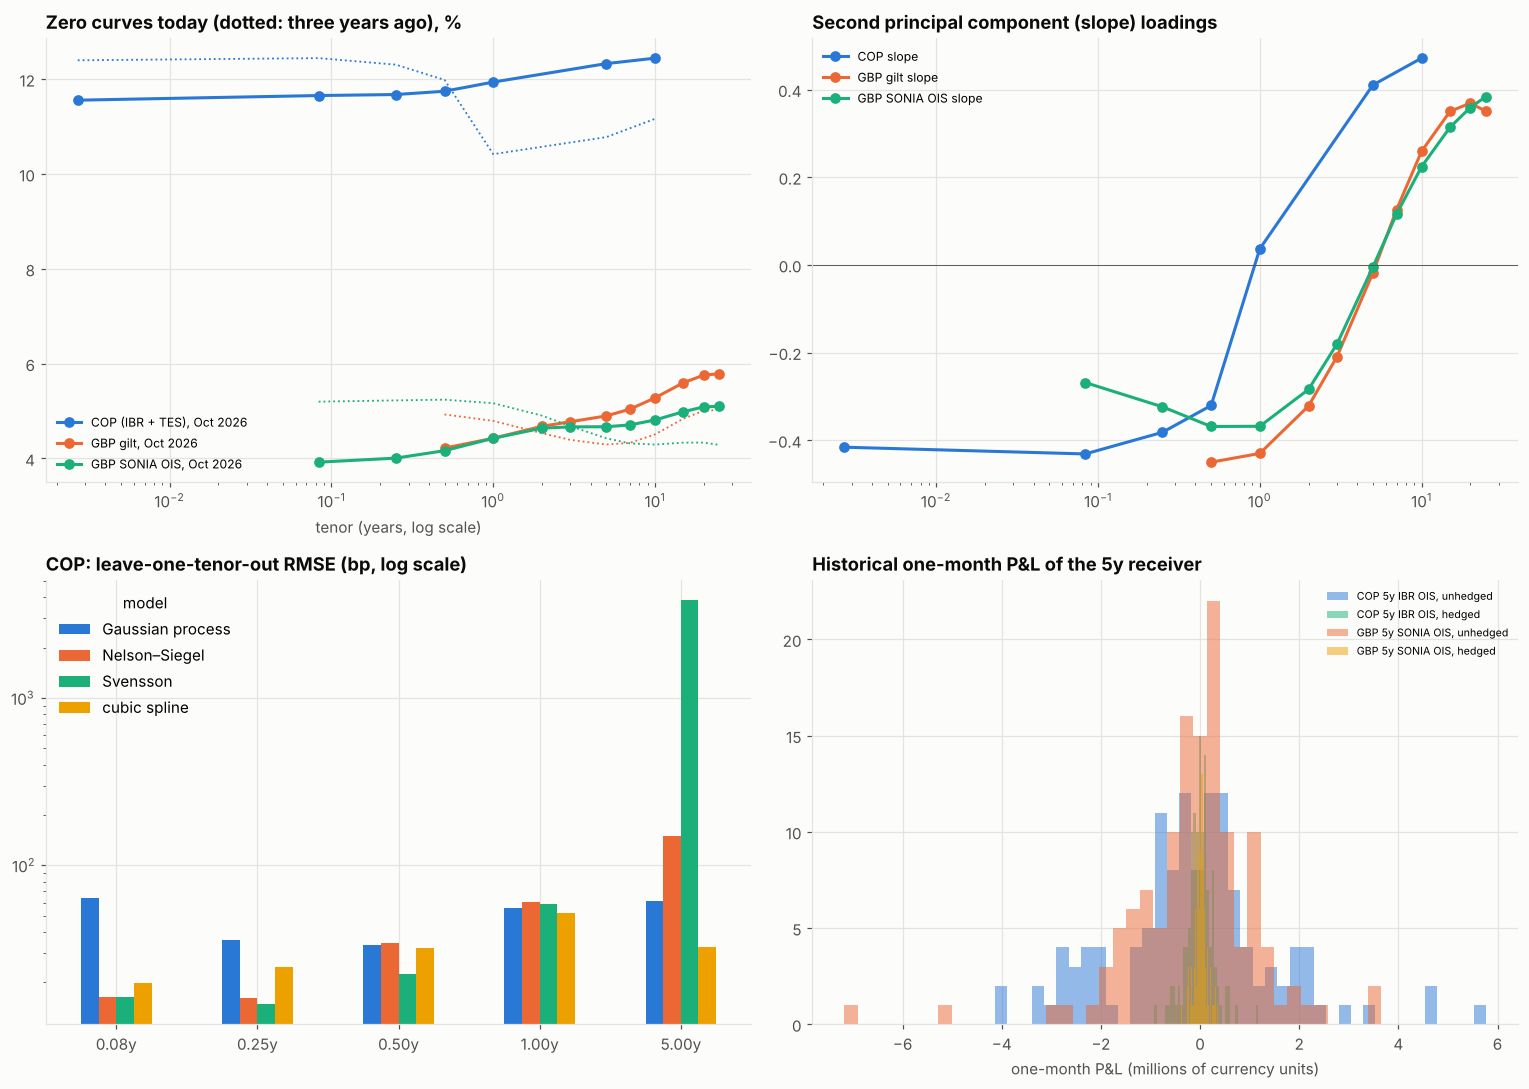

In [8]:
fig, ax = plt.subplots(2, 2, figsize=(14, 10))
a = ax[0, 0]
for i, (lab, df) in enumerate(
    {"COP (IBR + TES)": COPT, "GBP gilt": GILT, "GBP SONIA OIS": OIS}.items()
):
    a.plot(
        df.columns,
        df.iloc[-1],
        marker="o",
        color=PALETTE[i],
        label=f"{lab}, {df.index[-1]:%b %Y}",
    )
    yr = df.index[-1] - pd.DateOffset(years=3)
    if yr in df.index:
        a.plot(df.columns, df.loc[yr], color=PALETTE[i], ls=":", lw=1.2)
a.set_xscale("log")
a.set_xlabel("tenor (years, log scale)")
a.set_title("Zero curves today (dotted: three years ago), %")
a.legend(fontsize=8)
a = ax[0, 1]
for i, (lab, r) in enumerate(PCA_RES.items()):
    a.plot(
        r[1].index,
        r[1]["PC2"],
        marker="o",
        color=PALETTE[i],
        label=f"{lab} slope",
    )
a.set_xscale("log")
a.axhline(0, color=INK_2, lw=0.6)
a.set_title("Second principal component (slope) loadings")
a.legend(fontsize=8)
a = ax[1, 0]
FIT_TENOR.plot(kind="bar", ax=a, color=PALETTE[:4], rot=0)
a.set_yscale("log")
a.set_title("COP: leave-one-tenor-out RMSE (bp, log scale)")
a = ax[1, 1]
for i, (k, v) in enumerate(SW.items()):
    a.hist(
        v[2] / 1e6,
        bins=40,
        alpha=0.5,
        color=PALETTE[i],
        label=f"{k}, unhedged",
    )
    a.hist(
        v[3] / 1e6,
        bins=40,
        alpha=0.5,
        color=PALETTE[i + 2],
        label=f"{k}, hedged",
    )
a.set_xlabel("one-month P&L (millions of currency units)")
a.set_title("Historical one-month P&L of the 5y receiver")
a.legend(fontsize=7)
fig.tight_layout()
save_fig(fig, "01_rates_lab")
plt.show()

In [9]:
dash = make_subplots(
    rows=1,
    cols=2,
    subplot_titles=(
        "Policy rate, IBR overnight and TES 10y vs gilt 10y and SONIA 1y (%)",
        "Key-rate DV01 of the 5y receivers",
    ),
)
for i, (s, lab) in enumerate([
    (POLICY, "COP policy rate"),
    (COP["ibr_on"], "IBR overnight"),
    (COP["tes_10y"], "TES 10y zero"),
    (GILT[10.0], "gilt 10y zero"),
    (OIS[1.0], "SONIA OIS 1y"),
]):
    dash.add_trace(
        go.Scatter(x=s.index, y=s, name=lab, line=dict(color=PALETTE[i])), 1, 1
    )
for i, c in enumerate(KRD.columns):
    dash.add_trace(
        go.Bar(x=KRD.index, y=KRD[c], name=c, marker_color=PALETTE[i + 5]),
        1,
        2,
    )
dash.update_layout(
    height=600,
    width=1400,
    template="simple_white",
    title="COP and GBP rates lab",
)
save_dashboard(dash, "dashboard")
dash.show()

Dashboard saved: outputs/dashboard.html and .png


## 9. Reading the results and limitations

*Data are month-end; figures shift slightly as new months are published. The peso curve starts in May 2016, when the six-month IBR starts.*

**Two curves today (October 2026).**
- **Peso:** almost flat at a high level: 11.6% overnight, 11.9% at one year, 12.3% at five and 12.4% at ten (continuously compounded). Three years ago it was inverted, with money-market rates above 12% and the one-year TES zero at 10.4%.
- **Sterling:** SONIA swaps rise from 3.9% at one month to 4.7% at five years and 5.1% at 25 years. Gilts yield more than SONIA beyond two years, 0.7 points more at 25 years, the premium investors demand to hold long government bonds rather than swaps.

**What moves them.**

| Share of variance of monthly changes | Level | Slope | Curvature | First three |
|---|---|---|---|---|
| Peso (IBR + TES) | 59% | 27% | 6% | 92% |
| Sterling gilt | 81% | 14% | 4% | 98% |
| Sterling SONIA swaps | 86% | 9% | 4% | 99% |

- **The peso curve is two markets.** Money-market rates follow the policy rate almost one for one (correlation of monthly changes 0.996), while TES yields also move with fiscal and global risk. Hence a large slope factor and only 92% of variance in three factors.
- **Little in common across markets.** Level changes in the peso curve correlate only 0.33 with gilts and 0.35 with SONIA; ten-year yields 0.32.

**Drawing the curve between quotes (leave one tenor out).**

| RMSE (bp), predicting a removed quote | Cubic spline | Gaussian process | Nelson–Siegel | Svensson |
|---|---|---|---|---|
| Peso, 7 quoted tenors (since 2016) | 34 | 52 | 75 | 1,725 |
| Sterling gilt, 10 tenors (since 2015) | 1.8 | 1.6 | 4.9 | 2.6 |

- **With few quotes, flexibility hurts.** When the five-year TES point is removed, the peso curve has to bridge one to ten years: the spline misses by 33 bp, the Gaussian process by 61 and Nelson–Siegel by 150, while Svensson, with four parameters for six points, explodes (errors of tens of points). On the dense sterling curve all methods are within a few basis points.
- **The Gaussian process** adds an uncertainty band; it is slightly more accurate than the spline on the dense sterling curve but less accurate on the sparse peso curve; its value is in telling the desk where the curve is uncertain (the long end of the peso curve).

**Forecasting one month ahead.**

| RMSE (bp), all tenors | Random walk | Dynamic Nelson–Siegel | LightGBM |
|---|---|---|---|
| Peso (2019 to today) | 43.4 | 52.1 | 40.9 |
| Sterling gilt (2015 to today) | 26.8 | 28.4 | 30.4 |

- **Peso:** LightGBM beats the random walk by 6%, entirely at the short end (three-month IBR: 29 against 35 bp), because the gap between overnight rates and the policy rate signals the next policy move. It adds nothing at five and ten years.
- **Sterling:** nothing beats the random walk. The dynamic Nelson–Siegel model, which forecast well in the 1990s U.S. data it was built on, is worse than no change in both markets.

**Five-year receivers: value and risk (per 100 million of notional).**

| | Peso IBR OIS | Sterling SONIA OIS |
|---|---|---|
| Par rate | 12.47% | 4.78% |
| DV01 | COP 37,908 | GBP 45,651 |
| Key-rate DV01 at 5y / shorter tenors | 33,125 / 4,782 | 42,285 / 3,366 |
| One-month 99% VaR, unhedged | COP 3.8 million | GBP 4.5 million |
| VaR hedged for level and slope | COP 0.7 million (−82%) | GBP 0.3 million (−94%) |
| Hedge | pay 1y (0.76×) and 10y (0.55×) | pay 2y (1.10×) and 10y (0.34×) |

- **Most of the risk sits at the five-year point**, with the rest at the shorter tenors that discount the earlier coupons.
- **Hedging level and slope** with two other swaps removes 82% of the peso swap's tail risk and 94% of the sterling one's. The peso residual is larger because three factors explain less of its curve's moves.

**What this means for a rates desk.**
- **Peso curves need care between quotes.** Use a spline or Gaussian process rather than Svensson, and treat the 1–10-year region as uncertain until IBR swap quotes are available. TES-based long rates include a sovereign premium over swaps.
- **Do not expect statistical curve forecasts to beat no change,** except at the short end of the peso curve, where policy-rate expectations are informative.
- **Hedge by factors, not only by DV01.** Two hedging swaps chosen against level and slope cut value-at-risk by four-fifths or more.

**Limitations.**
- **Data:** no public IBR swap curve beyond one year, so the peso long end uses TES zero-coupon rates (published with 1 bp precision); the peso sample starts in 2016; Bank of England curves are smoothed fits rather than market quotes.
- **Models:** single-curve OIS valuation with linear interpolation of zero rates; value-at-risk from about 120 historical months, applied as absolute rate changes; forecasting models use few features and no macroeconomic data.

In [10]:
TODAY.to_csv(OUT_DIR / "zero_curves_today.csv")
PCA_T.to_csv(OUT_DIR / "pca_variance_shares.csv")
CORR.to_csv(OUT_DIR / "cross_market_correlations.csv")
FITCV.to_csv(OUT_DIR / "curve_fit_loto_rmse.csv")
FIT_TENOR.to_csv(OUT_DIR / "curve_fit_loto_rmse_cop_by_tenor.csv")
pd.concat({k: v[0] for k, v in FC.items()}).to_csv(
    OUT_DIR / "forecast_rmse_by_tenor.csv"
)
SWT.to_csv(OUT_DIR / "ois_valuation_and_risk.csv")
KRD.to_csv(OUT_DIR / "key_rate_dv01.csv")
print("Outputs written:", ", ".join(sorted(p.name for p in OUT_DIR.iterdir())))

Outputs written: 01_rates_lab.png, cross_market_correlations.csv, curve_fit_loto_rmse.csv, curve_fit_loto_rmse_cop_by_tenor.csv, dashboard.html, dashboard.png, forecast_rmse_by_tenor.csv, key_rate_dv01.csv, ois_valuation_and_risk.csv, pca_variance_shares.csv, zero_curves_today.csv


## References

- Anderson, N., & Sleath, J. (2001). *New estimates of the UK real and nominal yield curves* (Bank of England Working Paper No. 126). Bank of England.
- Diebold, F. X., & Li, C. (2006). Forecasting the term structure of government bond yields. *Journal of Econometrics*, 130(2), 337–364. https://doi.org/10.1016/j.jeconom.2005.03.005
- Ke, G., Meng, Q., Finley, T., Wang, T., Chen, W., Ma, W., Ye, Q., & Liu, T.-Y. (2017). LightGBM: A highly efficient gradient boosting decision tree. In *Advances in Neural Information Processing Systems 30* (pp. 3146–3154).
- Litterman, R., & Scheinkman, J. (1991). Common factors affecting bond returns. *Journal of Fixed Income*, 1(1), 54–61. https://doi.org/10.3905/jfi.1991.692347
- Nelson, C. R., & Siegel, A. F. (1987). Parsimonious modeling of yield curves. *Journal of Business*, 60(4), 473–489. https://doi.org/10.1086/296409
- Rasmussen, C. E., & Williams, C. K. I. (2006). *Gaussian processes for machine learning*. MIT Press.
- Svensson, L. E. O. (1994). *Estimating and interpreting forward interest rates: Sweden 1992–1994* (NBER Working Paper No. 4871). National Bureau of Economic Research. https://doi.org/10.3386/w4871
- Banco de la República. (2026). *Portal de estadísticas económicas* [Data: monetary policy rate, IBR, TES zero-coupon rates]. https://suameca.banrep.gov.co/estadisticas-economicas/
- Bank of England. (2026). *Yield curves* [Data: nominal government liability curve and OIS curve]. https://www.bankofengland.co.uk/statistics/yield-curves